# Explainability and SHAP

This notebook investigates the decision-making behavior of the final binary attack detection model using explainable artificial intelligence (XAI) techniques.

The primary objective is to determine which network traffic characteristics influence the model's attack predictions and to explain why individual traffic instances receive specific attack probability estimates.

SHAP (SHapley Additive exPlanations) is used as the primary explainability method. The analysis includes both global explanations of overall model behavior and local explanations of individual predictions.

# 1. Final Model and Data Preparation

The final F2-optimized Random Forest model and its selected feature set are loaded for explainability analysis.

The model is not retrained in this notebook. The objective is to explain the predictions of the previously trained final attack detection model.

In [1]:
from pathlib import Path
import json
import joblib
import pandas as pd
import numpy as np

model_dir = Path("models")
processed_dir = Path("data/processed")

final_rf_model = joblib.load(
    model_dir / "final_attack_detection_model.joblib"
)

with open(
    model_dir / "final_feature_columns.json",
    "r"
) as file:
    feature_columns = json.load(file)

print("Final model loaded successfully.")
print("Number of model features:", len(feature_columns))
print("Model type:", type(final_rf_model).__name__)

Final model loaded successfully.
Number of model features: 38
Model type: RandomForestClassifier


## 1.1. Explanation Dataset Preparation

A balanced subset of the independent test dataset is prepared for explainability analysis.

The complete test dataset is not used directly because SHAP computation can be computationally expensive and the original class distribution is highly imbalanced.

To ensure that both benign and attack behavior are adequately represented, 1,000 benign and 1,000 attack observations are randomly sampled for the explainability analysis.

This balanced subset is used only for model interpretation and does not alter the previously reported independent test performance.

In [2]:
test_path = processed_dir / "test_modeling.parquet"

df_test_shap = pd.read_parquet(
    test_path,
    columns=feature_columns + ["Label"]
)

benign_sample = (
    df_test_shap[df_test_shap["Label"] == 0]
    .sample(
        n=1000,
        random_state=42
    )
)

attack_sample = (
    df_test_shap[df_test_shap["Label"] == 1]
    .sample(
        n=1000,
        random_state=42
    )
)

explanation_data = pd.concat(
    [
        benign_sample,
        attack_sample
    ],
    ignore_index=True
)

X_explain = explanation_data[feature_columns]
y_explain = explanation_data["Label"]

print("Explanation dataset shape:", X_explain.shape)

print("\nClass distribution:")
print(
    y_explain.value_counts()
    .sort_index()
)

Explanation dataset shape: (2000, 38)

Class distribution:
Label
0    1000
1    1000
Name: count, dtype: int64


### 1.1. Findings

A balanced explanation dataset containing 2,000 independent test observations was successfully constructed.

The dataset contains 1,000 benign and 1,000 attack observations across the 38 features used by the final Random Forest model.

This balanced representation ensures that the explainability analysis considers both benign and malicious traffic behavior rather than being dominated by the highly imbalanced original test distribution.

# 2. SHAP-Based Model Explainability

SHAP is applied to quantify the contribution of individual network traffic features to the predictions produced by the final Random Forest classifier.

Because the final classifier is tree-based, `TreeExplainer` is used to efficiently compute feature-level SHAP values.

The analysis focuses primarily on the `Attack` class (`Label = 1`).

In [3]:
# %pip install shap

In [4]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.54.1


In [5]:
explainer = shap.TreeExplainer(
    final_rf_model
)

shap_values = explainer.shap_values(
    X_explain
)

print("SHAP values computed successfully.")
print("SHAP output type:", type(shap_values))

SHAP values computed successfully.
SHAP output type: <class 'numpy.ndarray'>


In [6]:
print("SHAP values shape:", shap_values.shape)
print("Expected value:", explainer.expected_value)

SHAP values shape: (2000, 38, 2)
Expected value: [0.00550198 0.99449802]


## 2.1. Attack-Class SHAP Value Extraction

The SHAP output contains separate feature contributions for the benign and attack classes.

Since the primary objective is to explain malicious traffic detection, the SHAP values corresponding to the attack class (`Label = 1`) are extracted for subsequent global and local explainability analyses.

In [7]:
attack_shap_values = shap_values[:, :, 1]

print(
    "Attack SHAP values shape:",
    attack_shap_values.shape
)

print(
    "Number of observations:",
    attack_shap_values.shape[0]
)

print(
    "Number of features:",
    attack_shap_values.shape[1]
)

Attack SHAP values shape: (2000, 38)
Number of observations: 2000
Number of features: 38


## 2.2. Global SHAP Feature Importance

Global feature importance is calculated using the mean absolute SHAP value of each feature across the explanation dataset.

This analysis identifies which network traffic characteristics have the greatest overall influence on the Random Forest model's attack predictions.

In [8]:
global_shap_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Mean_Absolute_SHAP": np.abs(
        attack_shap_values
    ).mean(axis=0)
})

global_shap_importance = (
    global_shap_importance
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    global_shap_importance.head(15)
)

,Feature,Mean_Absolute_SHAP
0,IAT,0.167496
1,rst_count,0.091758
2,psh_flag_number,0.028368
3,Header_Length,0.024389
4,Rate,0.023021
5,AVG,0.015022
6,Magnitue,0.014359
7,Tot sum,0.013550
8,Variance,0.013035
9,Tot size,0.012264


### 2.2. Findings

The global SHAP analysis identified `IAT` as the most influential feature in the final Random Forest model, with a mean absolute SHAP value of 0.1675.

The second most influential feature was `rst_count`, with a mean absolute SHAP value of 0.0918. These two features exhibited substantially greater overall influence than the remaining network traffic characteristics.

Other important features included `psh_flag_number`, `Header_Length`, `Rate`, `AVG`, `Magnitue`, `Tot sum`, and `Variance`.

These results indicate that temporal traffic behavior, connection-reset characteristics, packet flags, and traffic volume-related statistics contribute substantially to the model's attack predictions.

Mean absolute SHAP values quantify the magnitude of feature influence but do not indicate whether a particular feature value increases or decreases the predicted attack probability. Directional effects are examined in the subsequent SHAP analysis.

## 2.3. SHAP Summary Plot

A SHAP summary plot is used to examine both the magnitude and direction of feature contributions to the attack-class predictions.

Each point represents an individual observation. Its horizontal position represents the SHAP contribution, while the feature value indicates whether relatively high or low values are associated with changes in the model output.

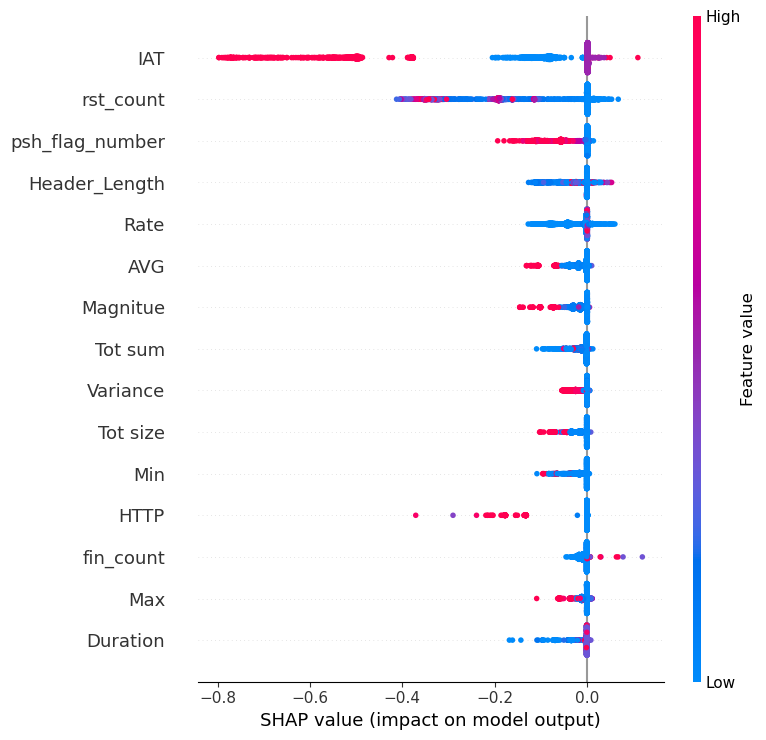

In [9]:
shap.summary_plot(
    attack_shap_values,
    X_explain,
    feature_names=feature_columns,
    max_display=15
)

### 2.3. Findings

The SHAP summary plot reveals clear directional patterns in how several network traffic features influence the model's attack predictions.

`IAT` exhibits the strongest directional effect. High `IAT` values are associated with strongly negative SHAP values, indicating that large inter-arrival times substantially reduce the model output toward the attack class. Lower `IAT` values generally have a weaker negative influence.

High values of `psh_flag_number`, `AVG`, `Magnitue`, `Tot size`, and particularly `HTTP` also tend to produce negative SHAP contributions, suggesting that these traffic characteristics frequently shift the model output away from the attack class.

In contrast, higher values of `Header_Length` and some `fin_count` observations are associated with SHAP values closer to or above zero, indicating that these conditions may contribute positively to the attack prediction in certain observations.

Features such as `rst_count` and `Rate` exhibit more heterogeneous SHAP patterns, suggesting that their effects are less strictly monotonic and may depend on interactions with other traffic characteristics.

Overall, the analysis demonstrates that the model's attack decisions are driven primarily by temporal behavior, reset-related activity, packet flags, header characteristics, and traffic-size statistics rather than by a single isolated feature.

## 2.4. Local SHAP Explanation

A local SHAP explanation is generated for an individual attack observation to determine why the final Random Forest model assigned its specific attack probability.

A representative attack instance with a predicted probability close to 0.87 is selected to illustrate how individual feature contributions influence a single model decision.

In [10]:
explanation_probabilities = final_rf_model.predict_proba(
    X_explain
)[:, 1]

attack_indices = np.where(
    y_explain.to_numpy() == 1
)[0]

target_probability = 0.87

local_index = attack_indices[
    np.argmin(
        np.abs(
            explanation_probabilities[attack_indices]
            - target_probability
        )
    )
]

local_probability = explanation_probabilities[
    local_index
]

print("Selected observation index:", local_index)
print("True Class: Attack")
print(
    "Predicted Attack Probability:",
    f"{local_probability:.4f}"
)

Selected observation index: 1856
True Class: Attack
Predicted Attack Probability: 0.9308


## 2.5. Local SHAP Waterfall Explanation

A SHAP waterfall plot is used to explain the selected attack observation at the individual prediction level.

The plot shows how each feature moves the model output away from the baseline prediction and contributes either positively or negatively to the final attack prediction.

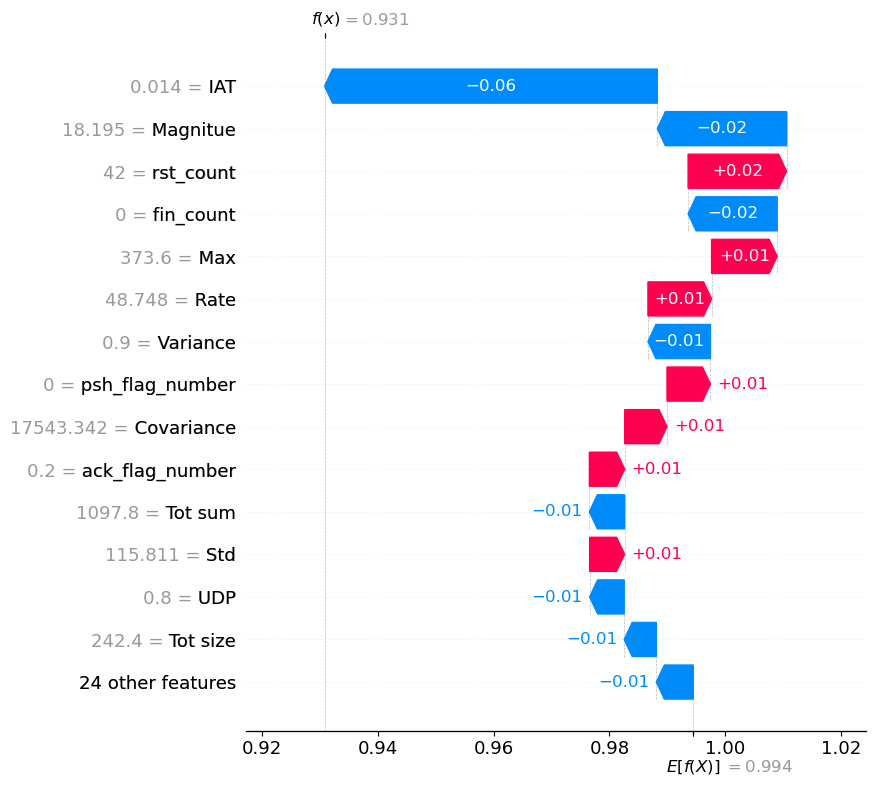

In [11]:
local_explanation = shap.Explanation(
    values=attack_shap_values[local_index],
    base_values=explainer.expected_value[1],
    data=X_explain.iloc[local_index].values,
    feature_names=feature_columns
)

shap.plots.waterfall(
    local_explanation,
    max_display=15
)

### 2.5. Findings

The local SHAP waterfall explanation shows how individual network traffic features contributed to the selected observation's predicted attack probability of approximately 0.931.

The strongest negative contribution was produced by `IAT`, which reduced the attack-class model output by approximately 0.06. `Magnitue` and `fin_count` also contributed negatively, each reducing the attack output by approximately 0.02.

In contrast, `rst_count` provided the strongest positive contribution, increasing the attack output by approximately 0.02. Additional positive contributions were observed from `Max`, `Rate`, `psh_flag_number`, `Covariance`, `ack_flag_number`, and `Std`.

The combined feature contributions shifted the model output from the baseline value of approximately 0.994 to a final attack output of approximately 0.931.

This local explanation demonstrates that the model's prediction is not determined by a single feature. Instead, the final attack probability results from the combined positive and negative contributions of multiple traffic characteristics.

## 2.6. Local SHAP Explanation for a Benign Observation

A correctly classified benign observation is analyzed using SHAP to identify which network traffic characteristics reduce the model output toward the attack class.

This provides a complementary explanation to the previously analyzed attack observation and helps illustrate how the model distinguishes benign and malicious traffic.

In [12]:
benign_indices = np.where(
    y_explain.to_numpy() == 0
)[0]

benign_probabilities = explanation_probabilities[
    benign_indices
]

benign_local_index = benign_indices[
    np.argmin(benign_probabilities)
]

benign_local_probability = explanation_probabilities[
    benign_local_index
]

print("Selected observation index:", benign_local_index)
print("True Class: Benign")
print(
    "Predicted Attack Probability:",
    f"{benign_local_probability:.4f}"
)

Selected observation index: 5
True Class: Benign
Predicted Attack Probability: 0.0000


benign_local_explanation = shap.Explanation(
    values=attack_shap_values[benign_local_index],
    base_values=explainer.expected_value[1],
    data=X_explain.iloc[benign_local_index].values,
    feature_names=feature_columns
)

shap.plots.waterfall(
    benign_local_explanation,
    max_display=15
)

### 2.6. Findings

The local SHAP explanation for the correctly classified benign observation shows that the model's attack output was reduced from a baseline value of approximately 0.994 to essentially zero.

The dominant contribution was produced by `IAT`, with a SHAP value of approximately -0.67. This indicates that the observed inter-arrival time strongly shifted the prediction away from the attack class.

Additional negative contributions were produced by `rst_count`, `Tot sum`, `Variance`, `Rate`, and `Min`, further reinforcing the benign prediction.

Unlike the previously analyzed attack observation, nearly all major feature contributions for this benign instance were negative with respect to the attack class.

This comparison demonstrates that the final Random Forest model distinguishes benign and malicious observations through different combinations and magnitudes of feature contributions, with `IAT` playing a particularly influential role in both global and local explanations.

## 2.7. Global SHAP Feature Importance Visualization

A SHAP bar plot is used to visualize the overall importance of the most influential network traffic features.

Feature importance is represented by the mean absolute SHAP value across the explanation dataset. Larger values indicate that a feature has a greater overall influence on the model's predictions.

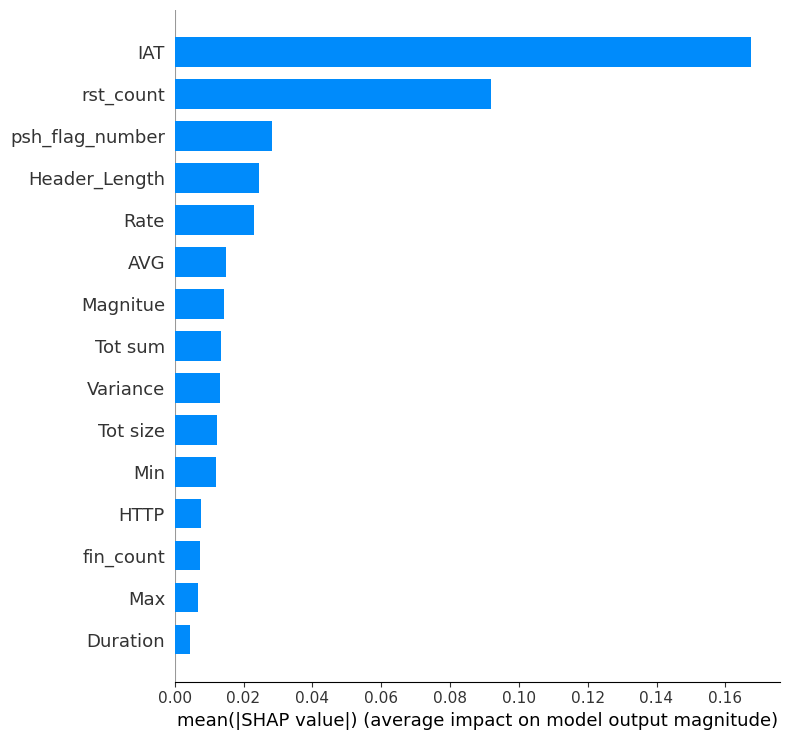

In [13]:
shap.summary_plot(
    attack_shap_values,
    X_explain,
    feature_names=feature_columns,
    plot_type="bar",
    max_display=15
)

### 2.7. Findings

The global SHAP bar plot confirms that `IAT` is the most influential feature in the final Random Forest model.

`IAT` has a substantially larger mean absolute SHAP value than the remaining features, indicating that temporal packet behavior plays a dominant role in the model's predictions.

The second most influential feature is `rst_count`, followed by `psh_flag_number`, `Header_Length`, and `Rate`.

The sharp decline in SHAP importance after the first two features suggests that the model relies particularly strongly on inter-arrival timing and reset-related traffic characteristics, while the remaining features provide complementary information.

## 2.8. Global and Local Explanation Summary

The SHAP analysis provides explanations at two complementary levels.

### Global Explanation

Global SHAP analysis identifies the network traffic characteristics that have the greatest overall influence on the final Random Forest model.

The most influential features were:

1. `IAT`
2. `rst_count`
3. `psh_flag_number`
4. `Header_Length`
5. `Rate`

Among these features, `IAT` exhibited the largest overall influence on the model's predictions, followed by `rst_count`.

These results provide insight into which traffic characteristics the model primarily relies on when distinguishing benign and malicious observations.

### Local Explanation

Local SHAP analysis explains individual model predictions by decomposing the final prediction into feature-level contributions.

For the selected attack observation, the model produced an attack probability of approximately 0.9308. The SHAP waterfall explanation demonstrated that this prediction resulted from a combination of positive and negative feature contributions rather than from a single network characteristic.

A correctly classified benign observation was also examined. In this case, several features, particularly `IAT`, strongly reduced the model output toward the attack class.

Together, the global and local analyses provide both an overall understanding of model behavior and an interpretable explanation for individual security decisions.

# 3. Conclusion

This notebook applied SHAP to explain the predictions of the final Random Forest attack detection model.

Global explainability analysis identified `IAT`, `rst_count`, `psh_flag_number`, `Header_Length`, and `Rate` as the most influential network traffic characteristics affecting model decisions.

Local SHAP explanations demonstrated how individual feature values contributed positively or negatively to specific attack probability estimates. This allows the model to provide not only an attack probability but also an explanation of the factors responsible for the prediction.

The resulting explainability framework therefore complements the binary attack detection system by answering two key questions:

- Which network characteristics influence the model's security decisions globally?
- Why was a specific traffic instance classified as suspicious or benign?

SHAP serves as the primary explainability method in this study and provides both global and instance-level transparency for the final attack detection model.